# Proyecto final · Predicción de partidos ATP
## Paso 6 · Evaluación y elección del modelo

Hasta ahora los modelos solo se compararon dentro del entrenamiento (2001–2022). Aquí se evalúan por primera vez en la **prueba: 2023–2026**, partidos que ningún modelo vio.

**Métricas**
| Métrica | Qué mide | Mejor |
|---|---|---|
| Exactitud | % de partidos donde acierta el ganador | Más alta |
| AUC | Si ordena bien: ¿le da más probabilidad al que termina ganando? | Más alta |
| Log loss | Castiga dar mucha confianza y fallar | Más baja |
| Brier | Error cuadrático de la probabilidad (0 = perfecto, 0,25 = moneda al aire) | Más baja |

La matriz de confusión no aporta aquí: como A y B se sortean al azar, no hay una clase "positiva" que importe más que la otra.

Al final, el **caso real: Roland Garros 2026**.

In [1]:
import os
import numpy as np
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss
import matplotlib.pyplot as plt

# Estilo de las gráficas: fondo claro, ejes discretos, texto en gris oscuro
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#898781"
TINTA, TINTA_2, REJILLA, EJE, FONDO = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlecolor": TINTA, "axes.titlelocation": "left",
})
coma = lambda v, f="{:+.1f}": f.format(v).replace(".", ",")

CARPETA = os.environ.get("TENIS_DATOS", "datos")
TORNEO_CASO, ANIO_CASO = "Roland Garros", 2026

paquete = joblib.load(os.path.join(CARPETA, "modelos.joblib"))
MODELOS = paquete["modelos"]
COLUMNAS = paquete["numericas"] + paquete["categoricas"]

datos = pd.read_csv(os.path.join(CARPETA, "tabla_modelo.csv.gz"), low_memory=False, parse_dates=["fecha"])
test = datos[datos["anio"] >= 2023].reset_index(drop=True)
y = test["gana_A"].values
print(f"Prueba 2023–2026: {len(test):,} partidos, de {test['fecha'].min().date()} a {test['fecha'].max().date()}")

# Probabilidad de que gane A según cada modelo
prob = {nombre: m.predict_proba(test[COLUMNAS])[:, 1] for nombre, m in MODELOS.items()}

Prueba 2023–2026: 10,329 partidos, de 2023-01-02 a 2026-05-25


### Resultados en la prueba

In [2]:
def fila(nombre, pred, p=None):
    r = {"Modelo": nombre, "Exactitud (%)": round(accuracy_score(y, pred) * 100, 2)}
    if p is not None:
        r.update({"AUC": round(roc_auc_score(y, p), 4), "Log loss": round(log_loss(y, p), 4),
                  "Brier": round(brier_score_loss(y, p), 4)})
    return r

pred_rank = np.where(test["dif_log_rank"] < 0, 1, np.where(test["dif_log_rank"] > 0, 0, 1))
pred_elo = np.where(test["dif_elo"] >= 0, 1, 0)

filas = [fila("Línea base (siempre A)", np.ones(len(test), dtype=int)),
         fila("Regla: mejor ranking", pred_rank),
         fila("Regla: mayor Elo", pred_elo)]
filas += [fila(n, (p >= 0.5).astype(int), p) for n, p in prob.items()]
resultados = pd.DataFrame(filas)

cv = pd.read_csv(os.path.join(CARPETA, "resultados_cv.csv"))
resultados["Exactitud en validación (%)"] = resultados["Modelo"].map(cv.set_index("Modelo")["exactitud"] * 100).round(2)
resultados

,Modelo,Exactitud (%),AUC,Log loss,Brier,Exactitud en validación (%)
0,Línea base (siempre A),49.04,NaN,NaN,NaN,49.74
1,Regla: mejor ranking,64.04,NaN,NaN,NaN,66.39
2,Regla: mayor Elo,65.14,NaN,NaN,NaN,68.00
3,Regresión logística,66.61,0.7328,0.6031,0.2087,69.48
4,Random forest,66.40,0.7315,0.6025,0.2087,69.55
5,XGBoost,66.43,0.7326,0.6023,0.2086,69.49


### ¿Cuál se elige?
Criterio, definido **antes** de ver la prueba:
1. La métrica principal es el **log loss**, porque el modelo entrega probabilidades y queremos que sean confiables, no solo acertar el ganador.
2. Si dos modelos quedan a menos de **0,002** en log loss, la diferencia es ruido, y se elige el **más simple**: logística, luego XGBoost, luego random forest.

In [3]:
SIMPLICIDAD = ["Regresión logística", "XGBoost", "Random forest"]
mod = resultados.dropna(subset=["Log loss"]).set_index("Modelo")
mejor_ll = mod["Log loss"].min()
empatados = mod.index[mod["Log loss"] <= mejor_ll + 0.002].tolist()
ELEGIDO = next(m for m in SIMPLICIDAD if m in empatados)

print(f"Mejor log loss: {mejor_ll:.4f}")
print(f"Empatados (a menos de 0,002): {empatados}")
print(f"\nMODELO ELEGIDO: {ELEGIDO}")
p_final = prob[ELEGIDO]
ganancia = (accuracy_score(y, (p_final >= 0.5).astype(int)) - accuracy_score(y, pred_rank)) * 100
print(f"Ganancia sobre la regla del ranking: {ganancia:+.2f} puntos de exactitud")

Mejor log loss: 0.6023
Empatados (a menos de 0,002): ['Regresión logística', 'Random forest', 'XGBoost']

MODELO ELEGIDO: Regresión logística
Ganancia sobre la regla del ranking: +2.57 puntos de exactitud


### ¿Qué tan seguros estamos? Intervalos de confianza
Una exactitud de 69 % en la prueba podría haber salido algo distinta con otros partidos. Para medir ese margen se usa **bootstrap**: se sortean los partidos de la prueba con reemplazo 1.000 veces, se recalcula la exactitud en cada sorteo y se toma el rango donde cae el 95 % de los resultados.

Interesan dos preguntas:
1. ¿El modelo es **realmente** mejor que las reglas, o la ventaja podría ser suerte? Si el intervalo de la ventaja queda **entero por encima de 0**, es real.
2. ¿Los tres modelos son realmente distintos entre sí? Si el intervalo de la diferencia **incluye el 0**, están empatados.

In [4]:
B = 1000
rng = np.random.default_rng(42)
aciertos = {"Línea base (siempre A)": (np.ones(len(test)) == y),
            "Regla: mejor ranking": (pred_rank == y),
            "Regla: mayor Elo": (pred_elo == y)}
aciertos.update({n: ((p >= 0.5).astype(int) == y) for n, p in prob.items()})
aciertos = {k: v.astype(float) for k, v in aciertos.items()}

reps = {k: np.empty(B) for k in aciertos}
for b in range(B):
    idx_b = rng.integers(0, len(test), len(test))
    for k, v in aciertos.items():
        reps[k][b] = v[idx_b].mean() * 100

ic = pd.DataFrame({k: {"Exactitud (%)": aciertos[k].mean() * 100,
                       "IC 95 % desde": np.percentile(r, 2.5), "IC 95 % hasta": np.percentile(r, 97.5)}
                   for k, r in reps.items()}).T.round(2)
print(f"Prueba 2023–2026: {len(test):,} partidos, {B} repeticiones de bootstrap")
ic

Prueba 2023–2026: 10,329 partidos, 1000 repeticiones de bootstrap


,Exactitud (%),IC 95 % desde,IC 95 % hasta
Línea base (siempre A),49.04,48.11,49.99
Regla: mejor ranking,64.04,63.14,64.96
Regla: mayor Elo,65.14,64.28,66.02
Regresión logística,66.61,65.72,67.53
Random forest,66.40,65.49,67.29
XGBoost,66.43,65.52,67.30


In [5]:
def ventaja(a, b):
    """Diferencia de exactitud a − b (en puntos), con su intervalo de 95 %."""
    d = reps[a] - reps[b]
    return {"Ventaja (puntos)": round((aciertos[a].mean() - aciertos[b].mean()) * 100, 2),
            "IC 95 % desde": round(np.percentile(d, 2.5), 2), "IC 95 % hasta": round(np.percentile(d, 97.5), 2),
            "% de repeticiones a favor": round((d > 0).mean() * 100, 1)}

comparaciones = {f"{ELEGIDO} vs. regla del ranking": ventaja(ELEGIDO, "Regla: mejor ranking"),
                 f"{ELEGIDO} vs. regla del Elo": ventaja(ELEGIDO, "Regla: mayor Elo")}
for otro in [m for m in MODELOS if m != ELEGIDO]:
    comparaciones[f"{ELEGIDO} vs. {otro}"] = ventaja(ELEGIDO, otro)
tabla_ventajas = pd.DataFrame(comparaciones).T

for nombre, f in tabla_ventajas.iterrows():
    veredicto = ("es MEJOR (el intervalo no incluye el 0)" if f["IC 95 % desde"] > 0 else
                 "es PEOR (el intervalo no incluye el 0)" if f["IC 95 % hasta"] < 0 else
                 "EMPATE (el intervalo incluye el 0)")
    print(f"{nombre}: {veredicto}")
tabla_ventajas

Regresión logística vs. regla del ranking: es MEJOR (el intervalo no incluye el 0)
Regresión logística vs. regla del Elo: es MEJOR (el intervalo no incluye el 0)
Regresión logística vs. Random forest: EMPATE (el intervalo incluye el 0)
Regresión logística vs. XGBoost: EMPATE (el intervalo incluye el 0)


,Ventaja (puntos),IC 95 % desde,IC 95 % hasta,% de repeticiones a favor
Regresión logística vs. regla del ranking,2.57,1.70,3.44,100.0
Regresión logística vs. regla del Elo,1.47,0.84,2.19,100.0
Regresión logística vs. Random forest,0.21,-0.28,0.73,79.5
Regresión logística vs. XGBoost,0.17,-0.25,0.60,79.0


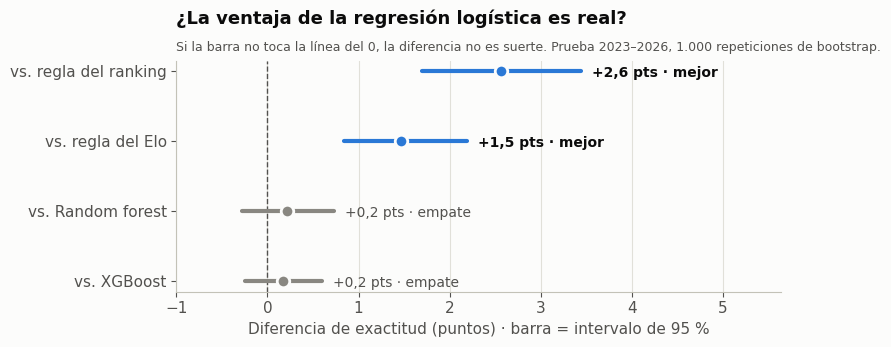

In [16]:
# Gráfica: intervalos de confianza de cada comparación
tv = tabla_ventajas.iloc[::-1]                       # la primera comparación queda arriba
real = tv["IC 95 % desde"] > 0
fig, ax = plt.subplots(figsize=(8.5, 3.6))
y_pos = np.arange(len(tv))
for yi, (nombre, f), ok in zip(y_pos, tv.iterrows(), real):
    color = AZUL if ok else GRIS
    ax.plot([f["IC 95 % desde"], f["IC 95 % hasta"]], [yi, yi], color=color, linewidth=3, solid_capstyle="round", zorder=2)
    ax.plot(f["Ventaja (puntos)"], yi, "o", color=color, markersize=9, markeredgecolor=FONDO, markeredgewidth=2, zorder=3)
    texto = f"{coma(f['Ventaja (puntos)'])} pts · {'mejor' if ok else 'empate'}"
    ax.annotate(texto, (f["IC 95 % hasta"], yi), textcoords="offset points", xytext=(8, -4),
                fontsize=10, color=TINTA if ok else TINTA_2, fontweight="bold" if ok else "normal")
ax.axvline(0, color=TINTA_2, linewidth=1, linestyle="--", zorder=1)
ax.set_yticks(y_pos)
ax.set_yticklabels([n.replace(f"{ELEGIDO} vs. ", "vs. ") for n in tv.index])
ax.set_xlabel("Diferencia de exactitud (puntos) · barra = intervalo de 95 %")
ax.set_xlim(min(-1, tv["IC 95 % desde"].min() - 0.5), tv["IC 95 % hasta"].max() + 2.2)
ax.grid(axis="y", visible=False)
ax.set_title(f"¿La ventaja de la {ELEGIDO.lower()} es real?", pad=26)
ax.text(0, 1.04, "Si la barra no toca la línea del 0, la diferencia no es suerte. Prueba 2023–2026, 1.000 repeticiones de bootstrap.",
        transform=ax.transAxes, fontsize=9, color=TINTA_2)
plt.tight_layout(); plt.show()

### ¿Las probabilidades son confiables? (calibración)
Si el modelo dice "70 %", el favorito debería ganar cerca del 70 % de esas veces. Se agrupan los partidos según la probabilidad que el modelo le dio al **favorito** y se compara con lo que pasó.

In [7]:
p_fav = np.maximum(p_final, 1 - p_final)                 # probabilidad del favorito según el modelo
gano_fav = np.where(p_final >= 0.5, y, 1 - y)
tramos = pd.cut(p_fav, [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 1.0], include_lowest=True)
calib = (pd.DataFrame({"tramo": tramos, "p": p_fav, "gano": gano_fav})
         .groupby("tramo", observed=True)
         .agg(partidos=("gano", "size"), prob_media=("p", "mean"), gano_favorito=("gano", "mean")))
calib["prob_media"] = (calib["prob_media"] * 100).round(1)
calib["gano_favorito"] = (calib["gano_favorito"] * 100).round(1)
calib.rename(columns={"prob_media": "Modelo dice (%)", "gano_favorito": "Pasó (%)"})

,partidos,Modelo dice (%),Pasó (%)
tramo,,,
"(0.499, 0.55]",1685,52.5,52.0
"(0.55, 0.6]",1617,57.4,57.2
"(0.6, 0.65]",1479,62.5,59.2
"(0.65, 0.7]",1338,67.4,66.4
"(0.7, 0.75]",1155,72.4,71.5
"(0.75, 0.8]",997,77.4,75.1
"(0.8, 0.85]",826,82.3,78.0
"(0.85, 0.9]",584,87.4,85.1
"(0.9, 1.0]",648,94.0,92.4


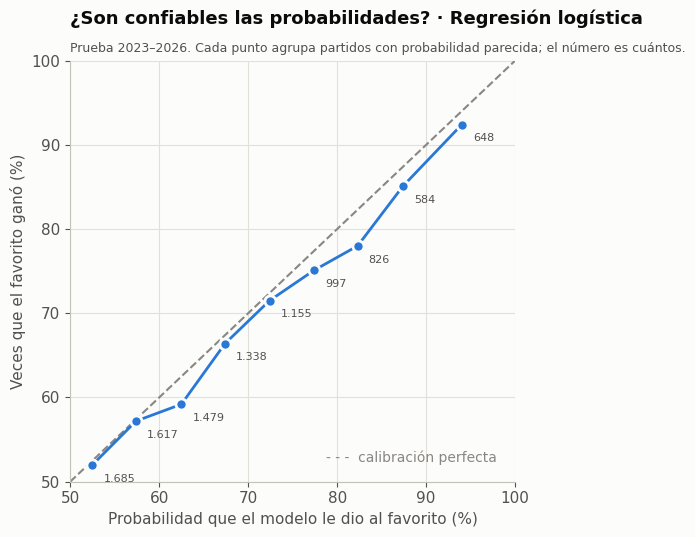

Si los puntos siguen la diagonal, cuando el modelo dice 70 % el favorito gana cerca del 70 % de las veces.


In [8]:
# Gráfica: curva de calibración
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([50, 100], [50, 100], color=GRIS, linestyle="--", linewidth=1.5, zorder=1)
ax.text(98, 52, "- - -  calibración perfecta", color=GRIS, ha="right", va="bottom", fontsize=10)
ax.plot(calib["prob_media"], calib["gano_favorito"], color=AZUL, linewidth=2, marker="o", markersize=8,
        markeredgecolor=FONDO, markeredgewidth=2, zorder=3)
for _, f in calib.iterrows():
    ax.annotate(f"{int(f['partidos']):,}".replace(",", "."), (f["prob_media"], f["gano_favorito"]),
                textcoords="offset points", xytext=(8, -12), fontsize=8, color=TINTA_2)
ax.set_xlim(50, 100); ax.set_ylim(50, 100)
ax.set_xlabel("Probabilidad que el modelo le dio al favorito (%)")
ax.set_ylabel("Veces que el favorito ganó (%)")
ax.set_title(f"¿Son confiables las probabilidades? · {ELEGIDO}", pad=26)
ax.text(0, 1.02, "Prueba 2023–2026. Cada punto agrupa partidos con probabilidad parecida; el número es cuántos.",
        transform=ax.transAxes, fontsize=9, color=TINTA_2)
plt.tight_layout(); plt.show()
print("Si los puntos siguen la diagonal, cuando el modelo dice 70 % el favorito gana cerca del 70 % de las veces.")

### ¿Dónde acierta y dónde falla?
Se compara el modelo con la regla del ranking en distintos tipos de partido.

In [9]:
acierto_m = ((p_final >= 0.5).astype(int) == y)
acierto_r = (pred_rank == y)

def comparar(grupo, orden=None):
    t = (pd.DataFrame({"g": grupo, "modelo": acierto_m, "ranking": acierto_r})
         .groupby("g", observed=True).agg(partidos=("modelo", "size"), modelo=("modelo", "mean"), ranking=("ranking", "mean")))
    t["Modelo (%)"] = (t["modelo"] * 100).round(1)
    t["Ranking (%)"] = (t["ranking"] * 100).round(1)
    t["Diferencia"] = (t["Modelo (%)"] - t["Ranking (%)"]).round(1)
    t = t[["partidos", "Modelo (%)", "Ranking (%)", "Diferencia"]]
    return t.reindex(orden).dropna() if orden else t

dif_rank = (np.exp(test["dif_log_rank"].abs()))          # cociente entre rankings: 1 = iguales
print("Según qué tan parejos eran por ranking (cociente entre los dos rankings):")
display(comparar(pd.cut(dif_rank, [1, 1.5, 2, 3, 5, np.inf], include_lowest=True,
                        labels=["< 1,5×", "1,5–2×", "2–3×", "3–5×", "> 5×"])))
print("Por superficie:")
display(comparar(test["superficie"]))
print("Por nivel del torneo (G = Grand Slam, M = Masters, A = ATP 250/500, D = Copa Davis, F = Finals, O = Olímpicos):")
display(comparar(test["nivel"]))
print("Por número de sets:")
display(comparar(test["best_of"]))

Según qué tan parejos eran por ranking (cociente entre los dos rankings):


,partidos,Modelo (%),Ranking (%),Diferencia
g,,,,
"< 1,5×",2407,58.3,52.9,5.4
"1,5–2×",1611,61.1,56.9,4.2
2–3×,1766,62.3,58.8,3.5
3–5×,1738,68.9,68.4,0.5
> 5×,2807,78.2,78.3,-0.1


Por superficie:


,partidos,Modelo (%),Ranking (%),Diferencia
g,,,,
Clay,3356,66.2,63.3,2.9
Grass,952,65.5,63.1,2.4
Hard,6021,67.0,64.6,2.4


Por nivel del torneo (G = Grand Slam, M = Masters, A = ATP 250/500, D = Copa Davis, F = Finals, O = Olímpicos):


,partidos,Modelo (%),Ranking (%),Diferencia
g,,,,
A,5038,65.4,62.1,3.3
D,806,68.1,65.9,2.2
F,75,64.0,61.3,2.7
G,1767,72.5,69.2,3.3
M,2580,64.3,63.5,0.8
O,63,74.6,74.6,0.0


Por número de sets:


,partidos,Modelo (%),Ranking (%),Diferencia
g,,,,
3,8521,65.4,63.0,2.4
5,1808,72.2,68.9,3.3


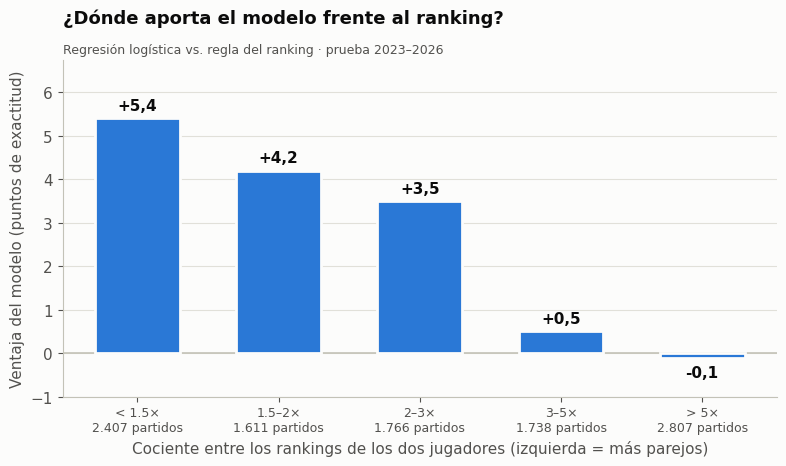

In [10]:
# Gráfica: ¿dónde aporta el modelo? Ventaja sobre el ranking según qué tan parejos eran los jugadores
etiquetas = ["< 1,5×", "1,5–2×", "2–3×", "3–5×", "> 5×"]
t1 = comparar(pd.cut(dif_rank, [1, 1.5, 2, 3, 5, np.inf], include_lowest=True, labels=etiquetas))

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(t1))
barras = ax.bar(x, t1["Diferencia"], width=0.6, color=AZUL, edgecolor=FONDO, linewidth=2, zorder=2)
ax.axhline(0, color=EJE, linewidth=1.2, zorder=1)
for xi, (_, f) in zip(x, t1.iterrows()):
    v = f["Diferencia"]
    ax.annotate(coma(v), (xi, v), textcoords="offset points", xytext=(0, 6 if v >= 0 else -14),
                ha="center", fontsize=11, fontweight="bold", color=TINTA)
ax.set_xticks(x)
ax.set_xticklabels([f"{e}\n{int(n):,} partidos".replace(",", ".") for e, n in zip(t1.index, t1["partidos"])], fontsize=9)
ax.set_xlabel("Cociente entre los rankings de los dos jugadores (izquierda = más parejos)")
ax.set_ylabel("Ventaja del modelo (puntos de exactitud)")
ax.set_title("¿Dónde aporta el modelo frente al ranking?", pad=26)
ax.text(0, 1.02, f"{ELEGIDO} vs. regla del ranking · prueba 2023–2026", transform=ax.transAxes, fontsize=9, color=TINTA_2)
ax.grid(axis="x", visible=False)
lim = max(abs(t1["Diferencia"]).max() * 1.25, 1)
ax.set_ylim(min(-1, t1["Diferencia"].min() * 1.4), lim)
plt.tight_layout(); plt.show()

---
## Caso real: Roland Garros 2026

El torneo se jugó entre mayo y junio de 2026. El modelo se entrenó con partidos hasta 2022, así que **nunca vio este torneo**: es como si lo hubiéramos corrido el día antes de cada partido.

In [11]:
rg = test[test["torneo"].str.contains(TORNEO_CASO, case=False, na=False) & (test["anio"] == ANIO_CASO)].copy()
print(f"{TORNEO_CASO} {ANIO_CASO}: {len(rg)} partidos")

if len(rg) == 0:
    print("No está en los datos: revise el nombre del torneo con test['torneo'].unique()")
else:
    i = rg.index.values
    rg["p_A"] = p_final[i]
    rg["ganador"] = np.where(rg["gana_A"] == 1, rg["A_name"], rg["B_name"])
    rg["perdedor"] = np.where(rg["gana_A"] == 1, rg["B_name"], rg["A_name"])
    rg["rank_ganador"] = np.where(rg["gana_A"] == 1, rg["A_rank"], rg["B_rank"])
    rg["rank_perdedor"] = np.where(rg["gana_A"] == 1, rg["B_rank"], rg["A_rank"])
    rg["p_ganador"] = np.where(rg["gana_A"] == 1, rg["p_A"], 1 - rg["p_A"])
    rg["acierta_modelo"] = rg["p_ganador"] >= 0.5
    rg["acierta_ranking"] = rg["rank_ganador"] < rg["rank_perdedor"]
    rg["acierta_elo"] = pred_elo[i] == y[i]

    # ¿Por qué no son 127? Un Grand Slam tiene 127 partidos de cuadro principal
    print("Partidos por ronda:", rg["ronda"].value_counts().reindex(["R128", "R64", "R32", "R16", "QF", "SF", "F"]).to_dict())
    print("(Esperado: R128 = 64, R64 = 32, R32 = 16, R16 = 8, QF = 4, SF = 2, F = 1. "
          "Los que faltan son walkovers eliminados en el paso 3.)")

Roland Garros 2026: 124 partidos
Partidos por ronda: {'R128': 64, 'R64': 30, 'R32': 16, 'R16': 8, 'QF': 4, 'SF': 1, 'F': 1}
(Esperado: R128 = 64, R64 = 32, R32 = 16, R16 = 8, QF = 4, SF = 2, F = 1. Los que faltan son walkovers eliminados en el paso 3.)


In [12]:
if len(rg):
    print(f"Exactitud en {TORNEO_CASO} {ANIO_CASO}:")
    print(f"   Modelo ({ELEGIDO}): {rg['acierta_modelo'].mean():.1%}")
    print(f"   Regla del ranking:  {rg['acierta_ranking'].mean():.1%}")
    print(f"   Regla del Elo:      {rg['acierta_elo'].mean():.1%}")
    i = rg.index.values
    print(f"   Log loss del modelo: {log_loss(y[i], p_final[i], labels=[0, 1]):.4f}")

    ORDEN = ["R128", "R64", "R32", "R16", "QF", "SF", "F"]
    por_ronda = (rg.groupby("ronda").agg(partidos=("ganador", "size"),
                                         modelo=("acierta_modelo", "mean"), ranking=("acierta_ranking", "mean"))
                 .reindex(ORDEN).dropna())
    por_ronda[["modelo", "ranking"]] = (por_ronda[["modelo", "ranking"]] * 100).round(1)
    display(por_ronda.rename(columns={"modelo": "Modelo (%)", "ranking": "Ranking (%)"}))

Exactitud en Roland Garros 2026:
   Modelo (Regresión logística): 66.1%
   Regla del ranking:  63.7%
   Regla del Elo:      65.3%
   Log loss del modelo: 0.6144


,partidos,Modelo (%),Ranking (%)
ronda,,,
R128,64,70.3,65.6
R64,30,63.3,63.3
R32,16,56.2,56.2
R16,8,75.0,50.0
QF,4,25.0,75.0
SF,1,100.0,100.0
F,1,100.0,100.0


### ¿Por qué Roland Garros solo no basta?
El mismo bootstrap, pero con los partidos de Roland Garros. Con unos 120 partidos, el margen de suerte es mucho más ancho que la ventaja que buscamos medir.

In [13]:
if len(rg):
    am = rg["acierta_modelo"].values.astype(float)
    ar = rg["acierta_ranking"].values.astype(float)
    rng_rg = np.random.default_rng(42)
    d_rg = np.empty(B)
    for b in range(B):
        k = rng_rg.integers(0, len(rg), len(rg))
        d_rg[b] = (am[k].mean() - ar[k].mean()) * 100
    f_test = tabla_ventajas.iloc[0]
    print(f"Ventaja del modelo sobre la regla del ranking (intervalo de 95 %):")
    print(f"   Prueba 2023–2026 ({len(test):,} partidos): {f_test['Ventaja (puntos)']:+.1f} puntos "
          f"({f_test['IC 95 % desde']:+.1f} a {f_test['IC 95 % hasta']:+.1f})  → ancho {f_test['IC 95 % hasta'] - f_test['IC 95 % desde']:.1f}")
    print(f"   {TORNEO_CASO} {ANIO_CASO} ({len(rg)} partidos):      {(am.mean() - ar.mean()) * 100:+.1f} puntos "
          f"({np.percentile(d_rg, 2.5):+.1f} a {np.percentile(d_rg, 97.5):+.1f})  → ancho {np.percentile(d_rg, 97.5) - np.percentile(d_rg, 2.5):.1f}")
    print(f"\nEl modelo y el ranking predicen distinto solo en {(am != ar).sum()} de los {len(rg)} partidos: "
          f"el resultado del torneo depende de esos pocos.")

Ventaja del modelo sobre la regla del ranking (intervalo de 95 %):
   Prueba 2023–2026 (10,329 partidos): +2.6 puntos (+1.7 a +3.4)  → ancho 1.7
   Roland Garros 2026 (124 partidos):      +2.4 puntos (-5.6 a +9.7)  → ancho 15.3

El modelo y el ranking predicen distinto solo en 23 de los 124 partidos: el resultado del torneo depende de esos pocos.


### El camino del campeón
¿Qué probabilidad le daba el modelo al campeón en cada ronda?

In [14]:
if len(rg):
    final = rg[rg["ronda"] == "F"]
    campeon = final["ganador"].iat[0] if len(final) else rg.sort_values("fecha")["ganador"].iat[-1]
    camino = (rg[rg["ganador"] == campeon]
              .assign(orden=lambda d: d["ronda"].map({r: k for k, r in enumerate(ORDEN)}))
              .sort_values("orden"))
    print(f"Campeón: {campeon}")
    display(camino[["ronda", "perdedor", "rank_ganador", "rank_perdedor", "p_ganador"]]
            .assign(p_ganador=lambda d: (d["p_ganador"] * 100).round(1))
            .rename(columns={"ronda": "Ronda", "perdedor": "Rival", "rank_ganador": "Ranking campeón",
                             "rank_perdedor": "Ranking rival", "p_ganador": "Prob. que le daba el modelo (%)"})
            .reset_index(drop=True))
    p_titulo = camino["p_ganador"].prod()
    print(f"Multiplicando las {len(camino)} probabilidades: el modelo le daba {p_titulo:.1%} de ganar el torneo con ese camino.")

Campeón: Alexander Zverev


,Ronda,Rival,Ranking campeón,Ranking rival,Prob. que le daba el modelo (%)
0,R128,Benjamin Bonzi,3.0,95.0,93.2
1,R64,Tomas Machac,3.0,43.0,82.6
2,R32,Quentin Halys,3.0,90.0,89.5
3,R16,Jesper De Jong,3.0,106.0,90.3
4,QF,Rafael Jodar,3.0,29.0,65.4
5,SF,Jakub Mensik,3.0,27.0,70.2
6,F,Flavio Cobolli,3.0,14.0,78.1


Multiplicando las 7 probabilidades: el modelo le daba 22.3% de ganar el torneo con ese camino.


### Las sorpresas
Los partidos donde el modelo falló con **más confianza**, y los que acertó cuando el ranking falló.

In [15]:
if len(rg):
    cols = ["ronda", "ganador", "rank_ganador", "perdedor", "rank_perdedor", "p_ganador"]
    nombres_cols = {"ronda": "Ronda", "ganador": "Ganó", "rank_ganador": "Rk", "perdedor": "Perdió",
                    "rank_perdedor": "Rk ", "p_ganador": "Prob. del ganador (%)"}

    print("Las 5 mayores sorpresas para el modelo (menor probabilidad que le dio al que ganó):")
    display(rg.nsmallest(5, "p_ganador")[cols].assign(p_ganador=lambda d: (d["p_ganador"] * 100).round(1))
            .rename(columns=nombres_cols).reset_index(drop=True))

    anticipo = rg[rg["acierta_modelo"] & ~rg["acierta_ranking"]]
    print(f"\nEl ranking falló pero el modelo acertó: {len(anticipo)} partidos")
    display(anticipo[cols].assign(p_ganador=lambda d: (d["p_ganador"] * 100).round(1))
            .rename(columns=nombres_cols).reset_index(drop=True))

    al_reves = rg[~rg["acierta_modelo"] & rg["acierta_ranking"]]
    print(f"\nEl ranking acertó pero el modelo falló: {len(al_reves)} partidos")
    display(al_reves[cols].assign(p_ganador=lambda d: (d["p_ganador"] * 100).round(1))
            .rename(columns=nombres_cols).reset_index(drop=True))

Las 5 mayores sorpresas para el modelo (menor probabilidad que le dio al que ganó):


,Ronda,Ganó,Rk,Perdió,Rk,Prob. del ganador (%)
0,R64,Juan Manuel Cerundolo,56.0,Jannik Sinner,1.0,4.3
1,R128,Adam Walton,97.0,Daniil Medvedev,8.0,9.4
2,R64,Moise Kouame,318.0,Adolfo Daniel Vallejo,71.0,9.9
3,R128,Moise Kouame,318.0,Marin Cilic,46.0,12.4
4,R32,Zachary Svajda,85.0,Francisco Cerundolo,26.0,16.7



El ranking falló pero el modelo acertó: 13 partidos


,Ronda,Ganó,Rk,Perdió,Rk,Prob. del ganador (%)
0,R128,Matteo Berrettini,105.0,Marton Fucsovics,65.0,70.1
1,R128,Jaime Faria,115.0,Denis Shapovalov,39.0,55.4
2,R128,Hubert Hurkacz,99.0,Jaume Munar,41.0,56.0
3,R128,Roman Andres Burruchaga,68.0,Sebastian Baez,64.0,52.6
4,R128,Yibing Wu,92.0,Marcos Giron,84.0,55.6
5,R128,Hamad Medjedovic,58.0,Yannick Hanfmann,53.0,62.4
6,R128,Quentin Halys,90.0,Mattia Bellucci,73.0,55.5
7,R128,Tomas Machac,43.0,Zizou Bergs,40.0,58.2
8,R64,Matteo Berrettini,105.0,Arthur Rinderknech,25.0,57.9
9,R64,Jaime Faria,115.0,Jan Lennard Struff,80.0,55.8



El ranking acertó pero el modelo falló: 10 partidos


,Ronda,Ganó,Rk,Perdió,Rk,Prob. del ganador (%)
0,R128,Luca Van Assche,100.0,Vilius Gaubas,133.0,46.7
1,R128,Hugo Gaston,118.0,Gael Monfils,218.0,43.8
2,R128,Camilo Ugo Carabelli,59.0,Emilio Nava,94.0,47.8
3,R128,Valentin Royer,74.0,Hugo Dellien,144.0,43.7
4,R128,Thiago Agustin Tirante,60.0,Pablo Llamas Ruiz,122.0,46.4
5,R64,Frances Tiafoe,22.0,Hubert Hurkacz,99.0,45.2
6,R64,Joao Fonseca,30.0,Dino Prizmic,72.0,46.4
7,R32,Flavio Cobolli,14.0,Learner Tien,18.0,46.8
8,QF,Matteo Arnaldi,104.0,Matteo Berrettini,105.0,43.6
9,QF,Jakub Mensik,27.0,Joao Fonseca,30.0,47.3


### Conclusión del paso 6 · Evaluación en la prueba (2023–2026)
 
Los modelos se evaluaron en **10.329 partidos que ninguno vio al entrenar**.
 
| Modelo | Exactitud | IC 95 % | AUC | Log loss | Brier | Exactitud en validación |
|---|---|---|---|---|---|---|
| Línea base (siempre A) | 49,04 % | 48,1 – 50,0 | – | – | – | 49,74 % |
| Regla: mejor ranking | 64,04 % | 63,1 – 65,0 | – | – | – | 66,39 % |
| Regla: mayor Elo | 65,14 % | 64,3 – 66,0 | – | – | – | 68,00 % |
| **Regresión logística** | **66,61 %** | **65,7 – 67,5** | **0,7328** | **0,6031** | **0,2087** | **69,48 %** |
| Random forest | 66,40 % | 65,5 – 67,3 | 0,7315 | 0,6025 | 0,2087 | 69,55 % |
| XGBoost | 66,43 % | 65,5 – 67,3 | 0,7326 | 0,6023 | 0,2086 | 69,49 % |
 
**Modelo elegido: regresión logística.** El criterio, fijado antes de ver la prueba, era el log loss, y entre modelos a menos de 0,002 se elige el más simple. XGBoost tiene el mejor log loss (0,6023), pero la logística está a solo 0,0008. Además es la más rápida, la más fácil de interpretar y tiene el mejor AUC.
 
**¿La ventaja es real?** (bootstrap de 1.000 repeticiones)
 
| Comparación | Ventaja | IC 95 % | Veredicto |
|---|---|---|---|
| vs. regla del ranking | +2,57 puntos | +1,70 a +3,44 | **Mejor** |
| vs. regla del Elo | +1,47 puntos | +0,84 a +2,19 | **Mejor** |
| vs. random forest | +0,21 puntos | −0,28 a +0,73 | Empate |
| vs. XGBoost | +0,17 puntos | −0,25 a +0,60 | Empate |
 
**¿Por qué todo baja unos 3 puntos respecto a la validación?** No es sobreajuste: las reglas, que no se entrenan, bajan lo mismo (el ranking pasa de 66,4 % a 64,0 %). La temporada 2023–2026 fue más pareja y difícil de predecir. Lo que importa se mantiene: **la ventaja sobre el ranking es de +3,1 puntos en validación y +2,6 en prueba.**
 
**Calibración:** las probabilidades son confiables hasta el 60 %. Por encima, el modelo es un poco sobreconfiado: cuando dice 82 %, el favorito gana el 78 % (exceso de 1 a 4 puntos). Es consistente con una prueba más pareja que el entrenamiento; se podría corregir recalibrando con años recientes.
 
**¿Dónde aporta el modelo?**
- **En los partidos parejos, como se planteó en el paso 1:** con rankings a menos de 1,5× de diferencia, el ranking acierta el 52,9 % (casi una moneda) y el modelo el **58,3 % (+5,4)**. En los partidos muy desiguales (más de 5×) no aporta (−0,1): ahí el ranking ya acierta el 78 %.
- **A 5 sets:** 72,2 % de exactitud y +3,3 sobre el ranking, contra 65,4 % y +2,4 a 3 sets. Los partidos largos favorecen al mejor jugador.
- **Por superficie:** aporta en las tres; un poco más en arcilla (+2,9), donde el Elo por superficie marca la diferencia.
- **Por nivel:** +3,3 en Grand Slams y en ATP 250/500, pero solo +0,8 en Masters, cuadros donde todos son jugadores top y el ranking ya los describe bien.
 
**Conclusión general:** el modelo supera de forma consistente y estadísticamente significativa a la regla del ranking (+2,6 puntos) y al Elo solo (+1,5). La ganancia se concentra en los partidos parejos, justo donde una regla simple no alcanza. Los tres modelos empatan: la relación entre las variables y el resultado es casi lineal, y por eso la regresión logística, el más simple, es suficiente.

### Caso real: Roland Garros 2026
 
El modelo nunca vio este torneo: es como si se hubiera usado el día antes de cada partido. Hubo **124 partidos** (los 3 que faltan para 127 son walkovers eliminados en el paso 3).
 
**Resultado:** el modelo superó a la regla del ranking por **+2,4 puntos**, casi lo mismo que en toda la prueba (+2,6). Solo predijeron distinto en **23 de los 124 partidos**: el modelo acertó 13 y el ranking 10.
 
**¿Por qué un torneo solo no basta para concluir?**
 
| | Partidos | Ventaja sobre el ranking | IC 95 % | Ancho |
|---|---|---|---|---|
| Prueba 2023–2026 | 10.329 | +2,6 puntos | +1,7 a +3,4 | 1,7 |
| Roland Garros 2026 | 124 | +2,4 puntos | −5,6 a +9,7 | 15,3 |
 
El resultado del torneo coincide con el general, pero su intervalo es 9 veces más ancho e incluye el 0. **La evidencia de que el modelo funciona es la prueba completa; Roland Garros es la ilustración.**
 
**El camino del campeón: Alexander Zverev (ranking 3)**
 
| Ronda | Rival (ranking) | Probabilidad que le daba el modelo |
|---|---|---|
| R128 | Benjamin Bonzi (95) | 93,2 % |
| R64 | Tomas Machac (43) | 82,6 % |
| R32 | Quentin Halys (90) | 89,5 % |
| R16 | Jesper De Jong (106) | 90,3 % |
| QF | Rafael Jódar (29) | 65,4 % |
| SF | Jakub Mensik (27) | 70,2 % |
| F | Flavio Cobolli (14) | 78,1 % |
 
El modelo fue favorito a Zverev en los 7 partidos. Ganar los 7 seguidos tenía una probabilidad de **22,3 %** (contando solo los rivales que de verdad enfrentó). Su partido más difícil según el modelo fue contra **Jódar**, a pesar de su ranking 29: en el Elo del paso 4, Jódar aparecía 7.º del mundo.
 
**Lo que el ranking no vio y el modelo sí (13 partidos):** el caso más claro es **Matteo Berrettini**, con ranking 105, que ganó 4 partidos que el ranking daba perdidos, incluido uno contra Rinderknech (25). El modelo acertó los 4 (uno con 70 % de confianza). Berrettini venía de lesiones: el ranking lo castigó por los torneos que no jugó, pero el Elo conserva el nivel de sus partidos. Lo mismo con Hurkacz (99).
 
**Lo que el modelo falló y el ranking acertó (10 partidos):** en todos, el modelo le daba al ganador entre 43,6 % y 47,8 %. Eran partidos casi a cara o sello: **el modelo falló dudando**, no con confianza.
 
**Las sorpresas que nadie anticipa:** Juan Manuel Cerúndolo (56) eliminó a **Jannik Sinner (1)** en segunda ronda, cuando el modelo le daba 4,3 %. Adam Walton (97) le ganó a Medvedev (9,4 %) y Moïse Kouamé (318) ganó dos partidos con menos del 13 %. El tenis tiene un componente de azar que ningún modelo elimina: una probabilidad del 4 % significa que pasa 1 de cada 25 veces.
 
## Conclusión final del proyecto
 
1. **¿Hace falta ML?** Sí, pero no en todos los partidos. La regla del ranking acierta el 64 % de los partidos de 2023–2026, y casi siempre en los desiguales. En los parejos es una moneda al aire (52,9 %), y ahí el modelo llega al 58,3 %.
2. **Lo que más aportó fue construir buenas variables, no elegir el algoritmo.** El Elo, calculado sin fugas sobre 30 años de partidos, ya supera al ranking por sí solo. Los tres modelos empatan entre sí.
3. **El modelo elegido, la regresión logística, supera de forma significativa al ranking (+2,6 puntos) y al Elo solo (+1,5)** en 10.329 partidos nuevos, y su ventaja es estable de la validación a la prueba.
4. **Limitaciones:** las probabilidades son algo sobreconfiadas por encima del 60 %, el Elo no sabe nada de jugadores sin partidos en una superficie, y el modelo no conoce lesiones ni condiciones del día. Como mejoras quedan recalibrar con años recientes, agregar las cuotas de las casas de apuestas como punto de comparación y actualizar los datos después de junio de 2026.